# Random input distributions through the OB core matrix

## Goal
Compare how the saved forward OB matrix changes independent Normal and Uniform feature distributions. Each row is one sample and each column is one feature. This experiment applies the same operation as `OBMatrix.__call__`: `X @ forward / size`. It does not run the windowing logic in `OBTransform` or any OBAF code.

The initial run uses the largest matching asset, size 2187. The original file named `ob_mx_243.safetensors` contained 81×81 matrices. Publication preparation replaced it with the verified 243×243 copy generated by `ob.py`.

## Context & Methods

### Key assumptions
- Input shape is `(n_samples, size)` and the saved forward matrix is `(size, size)`.
- Normal inputs have mean 0 and variance 1. Uniform inputs use `[-sqrt(3), sqrt(3)]`, giving the same mean and variance so the comparison focuses on distribution shape.
- The transformed output includes the `1 / size` factor used by `OBMatrix.__call__`. Shape plots standardize each feature to separate shape changes from scale changes. Raw output scale is reported separately.
- `N_SAMPLES=512` keeps the initial full-size matrix multiplication bounded; increase it after checking runtime and memory.

### 1. Parameters and imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import mlx.core as mx
import numpy as np

# Edit these parameters to explore another valid saved matrix.
SIZE = 2187
N_SAMPLES = 512
SEED = 42
MATRICES_DIR = Path("obf/matrices")

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.2})
rng = np.random.default_rng(SEED)
print(f"size={SIZE}, samples={N_SAMPLES}, estimated input array={N_SAMPLES * SIZE * 4 / 2**20:.1f} MiB")

size=2187, samples=512, estimated input array=4.3 MiB


### 2. Load and validate the saved matrix

In [2]:
matrix_path = MATRICES_DIR / f"ob_mx_{SIZE}.safetensors"
if not matrix_path.exists():
    raise FileNotFoundError(f"No saved OB matrix at {matrix_path}")

weights = mx.load(str(matrix_path))["forward"]
if weights.shape != (SIZE, SIZE):
    raise ValueError(f"Expected a {(SIZE, SIZE)} forward matrix, got {weights.shape}")
mx.eval(weights)
weights_np = np.asarray(weights)
column_norms = np.linalg.norm(weights_np, axis=0)
print(f"matrix={matrix_path}; shape={weights.shape}; dtype={weights.dtype}")
print(f"forward column L2 norms (min / median / max): {column_norms.min():.5g} / {np.median(column_norms):.5g} / {column_norms.max():.5g}")
print("Asset note: the historical malformed 243 file was replaced with its verified 243 x 243 copy.")

matrix=obf/matrices/ob_mx_2187.safetensors; shape=(2187, 2187); dtype=mlx.core.float32
forward column L2 norms (min / median / max): 46.765 / 66.136 / 66.136
Asset note: the historical malformed 243 file was replaced with its verified 243 x 243 copy.


### 3. Generate samples and apply the core transform

In [3]:
uniform_limit = np.sqrt(3.0)
inputs = {
    "Normal(0, 1)": rng.normal(loc=0.0, scale=1.0, size=(N_SAMPLES, SIZE)).astype(np.float32),
    "Uniform(-sqrt(3), sqrt(3))": rng.uniform(-uniform_limit, uniform_limit, size=(N_SAMPLES, SIZE)).astype(np.float32),
}

def apply_core_forward(samples):
    """Apply OBMatrix.__call__ semantics to a samples-by-features array."""
    mlx_samples = mx.array(samples)
    transformed = mx.matmul(mlx_samples, weights.astype(mlx_samples.dtype)) * (1.0 / SIZE)
    mx.eval(transformed)
    return np.asarray(transformed)

outputs = {name: apply_core_forward(samples) for name, samples in inputs.items()}
for name in inputs:
    print(f"{name}: input {inputs[name].shape} -> output {outputs[name].shape}")

Normal(0, 1): input (512, 2187) -> output (512, 2187)
Uniform(-sqrt(3), sqrt(3)): input (512, 2187) -> output (512, 2187)


## Results

### 4. Compare distribution shape
The plotted values are standardized within each feature (zero mean, unit variance). This makes the histogram comparison about shape rather than the matrix normalization or per-feature variance.

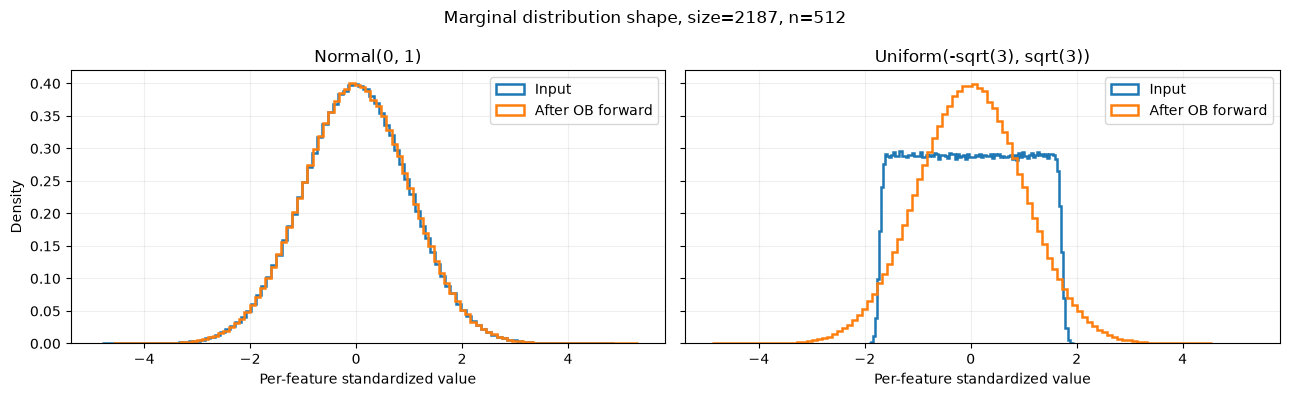

In [4]:
def per_feature_standardize(values):
    means = values.mean(axis=0, keepdims=True)
    stds = values.std(axis=0, keepdims=True)
    return (values - means) / np.maximum(stds, 1e-12)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True, sharey=True)
for ax, (name, samples) in zip(axes, inputs.items()):
    before = per_feature_standardize(samples).ravel()
    after = per_feature_standardize(outputs[name]).ravel()
    ax.hist(before, bins=100, density=True, histtype="step", linewidth=1.8, label="Input")
    ax.hist(after, bins=100, density=True, histtype="step", linewidth=1.8, label="After OB forward")
    ax.set_title(name)
    ax.set_xlabel("Per-feature standardized value")
    ax.legend()
axes[0].set_ylabel("Density")
fig.suptitle(f"Marginal distribution shape, size={SIZE}, n={N_SAMPLES}")
fig.tight_layout()
plt.show()

### 5. Measure scale and shape by feature
Means and standard deviations below are computed on the actual arrays, including the core `1 / size` scaling. Skewness and excess kurtosis are calculated per feature and summarized by their median.

In [5]:
def summarize(values):
    feature_means = values.mean(axis=0)
    feature_stds = values.std(axis=0)
    standardized = (values - feature_means) / np.maximum(feature_stds, 1e-12)
    feature_skew = np.mean(standardized ** 3, axis=0)
    feature_excess_kurtosis = np.mean(standardized ** 4, axis=0) - 3.0
    return {
        "pooled_mean": float(values.mean()),
        "pooled_std": float(values.std()),
        "feature_std_p05": float(np.quantile(feature_stds, 0.05)),
        "feature_std_median": float(np.median(feature_stds)),
        "feature_std_p95": float(np.quantile(feature_stds, 0.95)),
        "median_abs_feature_skew": float(np.median(np.abs(feature_skew))),
        "median_feature_excess_kurtosis": float(np.median(feature_excess_kurtosis)),
    }

for name in inputs:
    print(f"\n{name}")
    for stage, values in (("input", inputs[name]), ("core output", outputs[name])):
        print(stage, summarize(values))


Normal(0, 1)
input {'pooled_mean': 0.0004014225269202143, 'pooled_std': 1.0001863241195679, 'feature_std_p05': 0.9465512037277222, 'feature_std_median': 0.9983173608779907, 'feature_std_p95': 1.050022840499878, 'median_abs_feature_skew': 0.07388177514076233, 'median_feature_excess_kurtosis': -0.016643762588500977}
core output {'pooled_mean': 2.128290907421615e-05, 'pooled_std': 0.030248180031776428, 'feature_std_p05': 0.028575964272022247, 'feature_std_median': 0.030195508152246475, 'feature_std_p95': 0.03182408958673477, 'median_abs_feature_skew': 0.07565884292125702, 'median_feature_excess_kurtosis': -0.029802322387695312}

Uniform(-sqrt(3), sqrt(3))
input {'pooled_mean': 4.332459138822742e-05, 'pooled_std': 0.9997310042381287, 'feature_std_p05': 0.9647688865661621, 'feature_std_median': 0.999229907989502, 'feature_std_p95': 1.0313537120819092, 'median_abs_feature_skew': 0.04375399276614189, 'median_feature_excess_kurtosis': -1.1958872079849243}


core output {'pooled_mean': 3.1579049391439185e-05, 'pooled_std': 0.030215365812182426, 'feature_std_p05': 0.028611499816179276, 'feature_std_median': 0.030183181166648865, 'feature_std_p95': 0.031713638454675674, 'median_abs_feature_skew': 0.07083915174007416, 'median_feature_excess_kurtosis': -0.0308074951171875}


### 6. Apply the inverse matrix to Uniform data
Compare two paths: applying the inverse matrix directly to the original Uniform samples, and applying it after the forward transform. The inverse operation follows `OBMatrix.inverse` exactly and has no extra scaling.

In [6]:
inverse_weights = mx.load(str(matrix_path))["inverse"]
if inverse_weights.shape != weights.shape:
    raise ValueError(f"Forward/inverse shapes differ: {weights.shape} vs {inverse_weights.shape}")

def apply_core_inverse(spectrum):
    """Apply OBMatrix.inverse semantics to a samples-by-features array."""
    mlx_spectrum = mx.array(spectrum)
    restored = mx.matmul(mlx_spectrum, inverse_weights.astype(mlx_spectrum.dtype))
    mx.eval(restored)
    return np.asarray(restored)

uniform_name = "Uniform(-sqrt(3), sqrt(3))"
uniform_input = inputs[uniform_name]
uniform_forward = outputs[uniform_name]
uniform_inverse_direct = apply_core_inverse(uniform_input)
uniform_roundtrip = apply_core_inverse(uniform_forward)

def relative_l2_error(reference, candidate):
    return float(np.linalg.norm(candidate - reference) / np.linalg.norm(reference))

print(f"pooled std, original Uniform: {uniform_input.std():.6g}")
print(f"pooled std, direct inverse(original): {uniform_inverse_direct.std():.6g}")
print(f"pooled std, after forward: {uniform_forward.std():.6g}")
print(f"pooled std, after forward then inverse: {uniform_roundtrip.std():.6g}")
print(f"round-trip relative L2 error: {relative_l2_error(uniform_input, uniform_roundtrip):.6g}")
print(f"round-trip max absolute error: {np.max(np.abs(uniform_input - uniform_roundtrip)):.6g}")
for label, values in (("original Uniform", uniform_input), ("direct inverse", uniform_inverse_direct), ("forward then inverse", uniform_roundtrip)):
    print(f"\n{label}: {summarize(values)}")
normal_name = "Normal(0, 1)"
normal_input = inputs[normal_name]
normal_inverse_direct = apply_core_inverse(normal_input)
normal_roundtrip = apply_core_inverse(outputs[normal_name])
print(f"\npooled std, original Normal: {normal_input.std():.6g}")
print(f"pooled std, direct inverse(Normal): {normal_inverse_direct.std():.6g}")
print(f"Normal round-trip relative L2 error: {relative_l2_error(normal_input, normal_roundtrip):.6g}")
print(f"Normal direct inverse summary: {summarize(normal_inverse_direct)}")

pooled std, original Uniform: 0.999731
pooled std, direct inverse(original): 38.195
pooled std, after forward: 0.0302154
pooled std, after forward then inverse: 0.999731
round-trip relative L2 error: 1.19643e-06
round-trip max absolute error: 3.24249e-05



original Uniform: {'pooled_mean': 4.332459138822742e-05, 'pooled_std': 0.9997310042381287, 'feature_std_p05': 0.9647688865661621, 'feature_std_median': 0.999229907989502, 'feature_std_p95': 1.0313537120819092, 'median_abs_feature_skew': 0.04375399276614189, 'median_feature_excess_kurtosis': -1.1958872079849243}

direct inverse: {'pooled_mean': 0.0690641701221466, 'pooled_std': 38.19501495361328, 'feature_std_p05': 36.19368362426758, 'feature_std_median': 38.12773132324219, 'feature_std_p95': 40.12581253051758, 'median_abs_feature_skew': 0.07229152321815491, 'median_feature_excess_kurtosis': -0.04124259948730469}

forward then inverse: {'pooled_mean': 4.3325271690264344e-05, 'pooled_std': 0.9997310638427734, 'feature_std_p05': 0.9647690653800964, 'feature_std_median': 0.999230146408081, 'feature_std_p95': 1.0313535928726196, 'median_abs_feature_skew': 0.04375405237078667, 'median_feature_excess_kurtosis': -1.1958857774734497}

pooled std, original Normal: 1.00019
pooled std, direct inv

### 7. Compare shape before and after inverse

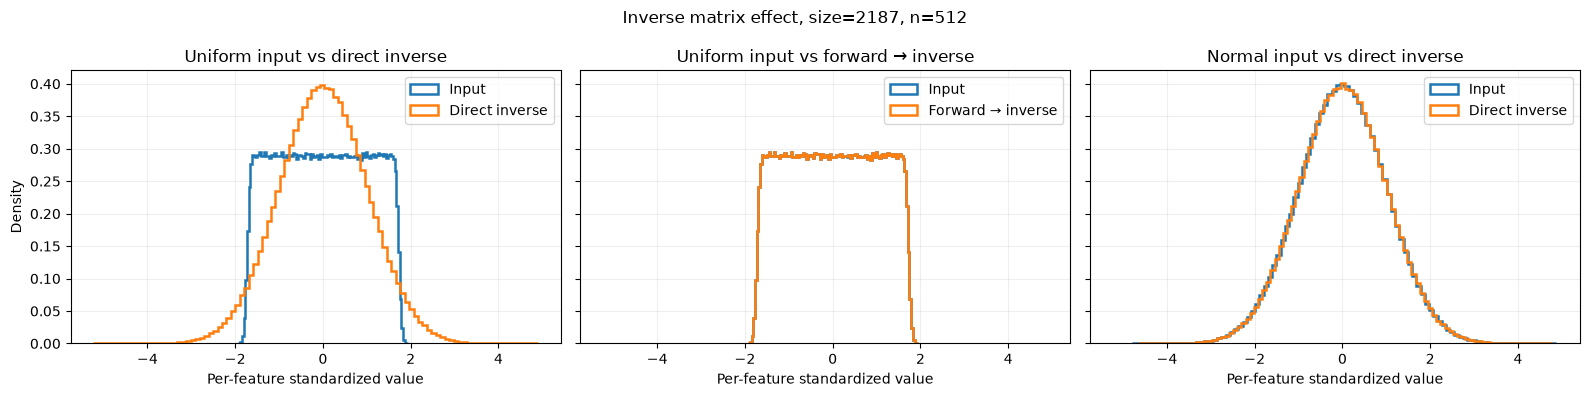

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
comparisons = [
    (axes[0], "Uniform input vs direct inverse", uniform_input, uniform_inverse_direct, "Direct inverse"),
    (axes[1], "Uniform input vs forward → inverse", uniform_input, uniform_roundtrip, "Forward → inverse"),
    (axes[2], "Normal input vs direct inverse", normal_input, normal_inverse_direct, "Direct inverse"),
]
for ax, title, before, after, after_label in comparisons:
    ax.hist(per_feature_standardize(before).ravel(), bins=100, density=True, histtype="step", linewidth=1.8, label="Input")
    ax.hist(per_feature_standardize(after).ravel(), bins=100, density=True, histtype="step", linewidth=1.8, label=after_label)
    ax.set_title(title)
    ax.set_xlabel("Per-feature standardized value")
    ax.legend()
axes[0].set_ylabel("Density")
fig.suptitle(f"Inverse matrix effect, size={SIZE}, n={N_SAMPLES}")
fig.tight_layout()
plt.show()

## Takeaways

In the executed run (size 2187, 512 samples), the Normal input remained Normal-shaped after applying the inverse matrix directly; its median per-feature excess kurtosis stayed close to zero. The pooled standard deviation increased from about `1.00` to `38.2`, reflecting the inverse matrix scale. This matches the linear algebra: a fixed linear map of a multivariate Normal remains multivariate Normal, with transformed covariance.

The Uniform input also became much closer to Normal after either forward or inverse matrix mixing: median per-feature excess kurtosis moved from about `-1.20` to about `-0.04`. Applying forward and then inverse reconstructed the original Uniform samples almost exactly: relative L2 error `1.2e-6`, maximum absolute error `3.2e-5`.

The core forward output scale is dominated by its `1 / 2187` factor: pooled standard deviations were `0.03025` for Normal and `0.03022` for Uniform inputs. The saved forward matrix has column L2 norms from `46.765` to `66.136`, so per-feature output scale is not perfectly uniform.

The historical malformed 243 asset was replaced with a verified 243×243 copy during publication preparation. These results cover independent synthetic features and one matrix; they do not establish behavior for correlated features or real datasets.